# Week 3: Linear & Polynomial Regression on Real Data

**Instructor:** Dr. Mahmoud Eid (m.eid@fci-cu.edu.eg)

<div dir="rtl" style="text-align: right; font-size: 0.9em; color: #888; margin: 10px 0;">
Week 3:
 الـ Linear و Polynomial Regression على data حقيقية </div>

Welcome to Week 3! 🎯 This we're working with an **actual real-world dataset** for the first time! .. Everything you learned in Weeks 1 and 2 will now be applied to this regression problems containing data for 20,000+ real houses.

## What You Learned in Previous Weeks

Revise those before the current week if needed.

**Week 1 (Python Fundamentals - Lectures 1-2):**
- Variables and data types
- Lists and indexing → Now we'll use NumPy arrays!
- **Loops** → We'll use them for training iterations (epochs)
- **Functions** → We'll create prediction and cost functions

**Week 2 (NumPy & Visualization - Lectures 3-4):**
- **NumPy arrays** → Perfect for storing features and predictions!
- **Vectorization** → Makes our gradient descent FAST!
- **Broadcasting** → Simplifies weight updates
- **Matplotlib** → We'll visualize regressions, loss curves, and more!
- **Statistical operations** (mean, std, correlation)

## Today's Journey (Lectures 3-4 Material)

**Lecture 3:** Linear & Polynomial Regression  
**Lecture 4:** Gradient Descent & Optimizers

<div dir="rtl" style="text-align: right; font-size: 0.9em; color: #aaa; margin: 10px 0;">في Lectures 3 و 4 اتعلمت النظري - النهاردة هنطبقها على data حقيقية بإذن الله!</div>

**Today's goal:** See these concepts working on REAL data - not synthetic examples!

## What We'll Build

1. **Load real housing data** (California Housing dataset - 20,640 actual houses!)
2. **Explore correlations** between features and prices
3. **Build linear regression from scratch** using gradient descent (Lecture 3)
4. **Try polynomial regression** and see overfitting
5. **Compare optimizers** (Batch GD, SGD, Mini-batch, Momentum, RMSprop, Adam) from Lecture 4
6. **Use sklearn and Pytorch** to see how professionals do it
7. **Practice** with different features

**Estimated Time:** 3 to 4 hours


Let's begin! 🚀

---

## Part 1: Loading Real Data

In Weeks 1 and 2, we worked with small synthetic datasets. Today, we'll use the **California Housing Dataset** - a real dataset with actual housing prices!

**What's in this dataset?**
- **20,640 houses** in California
- **8 features** like income, house age, number of rooms
- **Target:** Median house price

This is what data scientists work with every day!

In [35]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing
from sklearn.linear_model import LinearRegression, SGDRegressor
from mpl_toolkits.mplot3d import Axes3D

# PyTorch for optimizers comparison .. PyTorch is one of the most important frameworks that we will use
import torch
from torch import nn, optim

plt.style.use('dark_background') # Dark theme

# For reproducibility
np.random.seed(42)
torch.manual_seed(42)

print("All libraries loaded successfully!")
print(f"NumPy version: {np.__version__}")
print(f"PyTorch version: {torch.__version__}")

All libraries loaded successfully!
NumPy version: 2.1.3
PyTorch version: 2.9.1+cu126


In [36]:
plt.style.use("dark_background")
np.random.seed(42)

california_data = fetch_california_housing()

X = california_data.data
y = california_data.target

feature_names = california_data.feature_names

print(f"Number of Samples: {X.shape[0]:,}")
print(f"Number of Features: {X.shape[1]}")
print(f"Feature Names:\n{feature_names}")

print(f"\nFeature descriptions:")
print(f"  0: MedInc      - Median income in block group (in $10,000s)")
print(f"  1: HouseAge    - Median house age in block group (in years)")
print(f"  2: AveRooms    - Average number of rooms per household")
print(f"  3: AveBedrms   - Average number of bedrooms per household")
print(f"  4: Population  - Block group population")
print(f"  5: AveOccup    - Average number of household members")
print(f"  6: Latitude    - Block group latitude")
print(f"  7: Longitude   - Block group longitude")
print(f"\nTarget: Median house value (in $100,000s)")
print(f"\nExample: MedInc=3.5 means median income is $35,000")

Number of Samples: 20,640
Number of Features: 8
Feature Names:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']

Feature descriptions:
  0: MedInc      - Median income in block group (in $10,000s)
  1: HouseAge    - Median house age in block group (in years)
  2: AveRooms    - Average number of rooms per household
  3: AveBedrms   - Average number of bedrooms per household
  4: Population  - Block group population
  5: AveOccup    - Average number of household members
  6: Latitude    - Block group latitude
  7: Longitude   - Block group longitude

Target: Median house value (in $100,000s)

Example: MedInc=3.5 means median income is $35,000


In [37]:
print("First 5 Houses: ")
for i in range(5):
    print(f"House {i + 1}")
    for j, name in enumerate(feature_names):
        print(f"    {name}: {X[i, j]:.2f}")
    print(f"--> Price: ${y[i]*100000:,.0f}")
    print()

First 5 Houses: 
House 1
    MedInc: 8.33
    HouseAge: 41.00
    AveRooms: 6.98
    AveBedrms: 1.02
    Population: 322.00
    AveOccup: 2.56
    Latitude: 37.88
    Longitude: -122.23
--> Price: $452,600

House 2
    MedInc: 8.30
    HouseAge: 21.00
    AveRooms: 6.24
    AveBedrms: 0.97
    Population: 2401.00
    AveOccup: 2.11
    Latitude: 37.86
    Longitude: -122.22
--> Price: $358,500

House 3
    MedInc: 7.26
    HouseAge: 52.00
    AveRooms: 8.29
    AveBedrms: 1.07
    Population: 496.00
    AveOccup: 2.80
    Latitude: 37.85
    Longitude: -122.24
--> Price: $352,100

House 4
    MedInc: 5.64
    HouseAge: 52.00
    AveRooms: 5.82
    AveBedrms: 1.07
    Population: 558.00
    AveOccup: 2.55
    Latitude: 37.85
    Longitude: -122.25
--> Price: $341,300

House 5
    MedInc: 3.85
    HouseAge: 52.00
    AveRooms: 6.28
    AveBedrms: 1.08
    Population: 565.00
    AveOccup: 2.18
    Latitude: 37.85
    Longitude: -122.25
--> Price: $342,200



In [38]:
california_data = fetch_california_housing(as_frame=True)

X_df = california_data.data
y_df = california_data.target

data = X_df.copy()
data[y_df.name] = y_df

print(data.head())

# Saving Data
data.to_csv("data/california_housing.csv", index=False)

   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  


In [39]:
print("Features Statistics:\n")
print(data.describe().T.round(2).drop("count", axis=1))

Features Statistics:

                mean      std     min     25%      50%      75%       max
MedInc          3.87     1.90    0.50    2.56     3.53     4.74     15.00
HouseAge       28.64    12.59    1.00   18.00    29.00    37.00     52.00
AveRooms        5.43     2.47    0.85    4.44     5.23     6.05    141.91
AveBedrms       1.10     0.47    0.33    1.01     1.05     1.10     34.07
Population   1425.48  1132.46    3.00  787.00  1166.00  1725.00  35682.00
AveOccup        3.07    10.39    0.69    2.43     2.82     3.28   1243.33
Latitude       35.63     2.14   32.54   33.93    34.26    37.71     41.95
Longitude    -119.57     2.00 -124.35 -121.80  -118.49  -118.01   -114.31
MedHouseVal     2.07     1.15    0.15    1.20     1.80     2.65      5.00


---

## Exploratory Data Analysis (EDA)

## Part 2: Correlation Analysis

Before building a model, let's explore the data visually! This is a critical step in any ML project.

**Question:** Which features are most correlated with house prices?

Recall from the first lecture that **Correlation** measures how two variables move/change together:
- **+1:** Perfect positive correlation (both increase together)
- **0:** No correlation
- **-1:** Perfect negative correlation (one increases, other decreases)

You learned about correlation in **Week 1** - now let's use it!

In [40]:
correlations = []
for i in range(X.shape[1]):
    corr = np.corrcoef(X[:, i], y)[0, 1]
    correlations.append(float(corr))

for i, name in enumerate(feature_names):
    print(f"{name}: {correlations[i]:3f}")

MedInc: 0.688075
HouseAge: 0.105623
AveRooms: 0.151948
AveBedrms: -0.046701
Population: -0.024650
AveOccup: -0.023737
Latitude: -0.144160
Longitude: -0.045967


In [41]:
print(data.iloc[:, :-1].corrwith(data["MedHouseVal"]))

MedInc        0.688075
HouseAge      0.105623
AveRooms      0.151948
AveBedrms    -0.046701
Population   -0.024650
AveOccup     -0.023737
Latitude     -0.144160
Longitude    -0.045967
dtype: float64


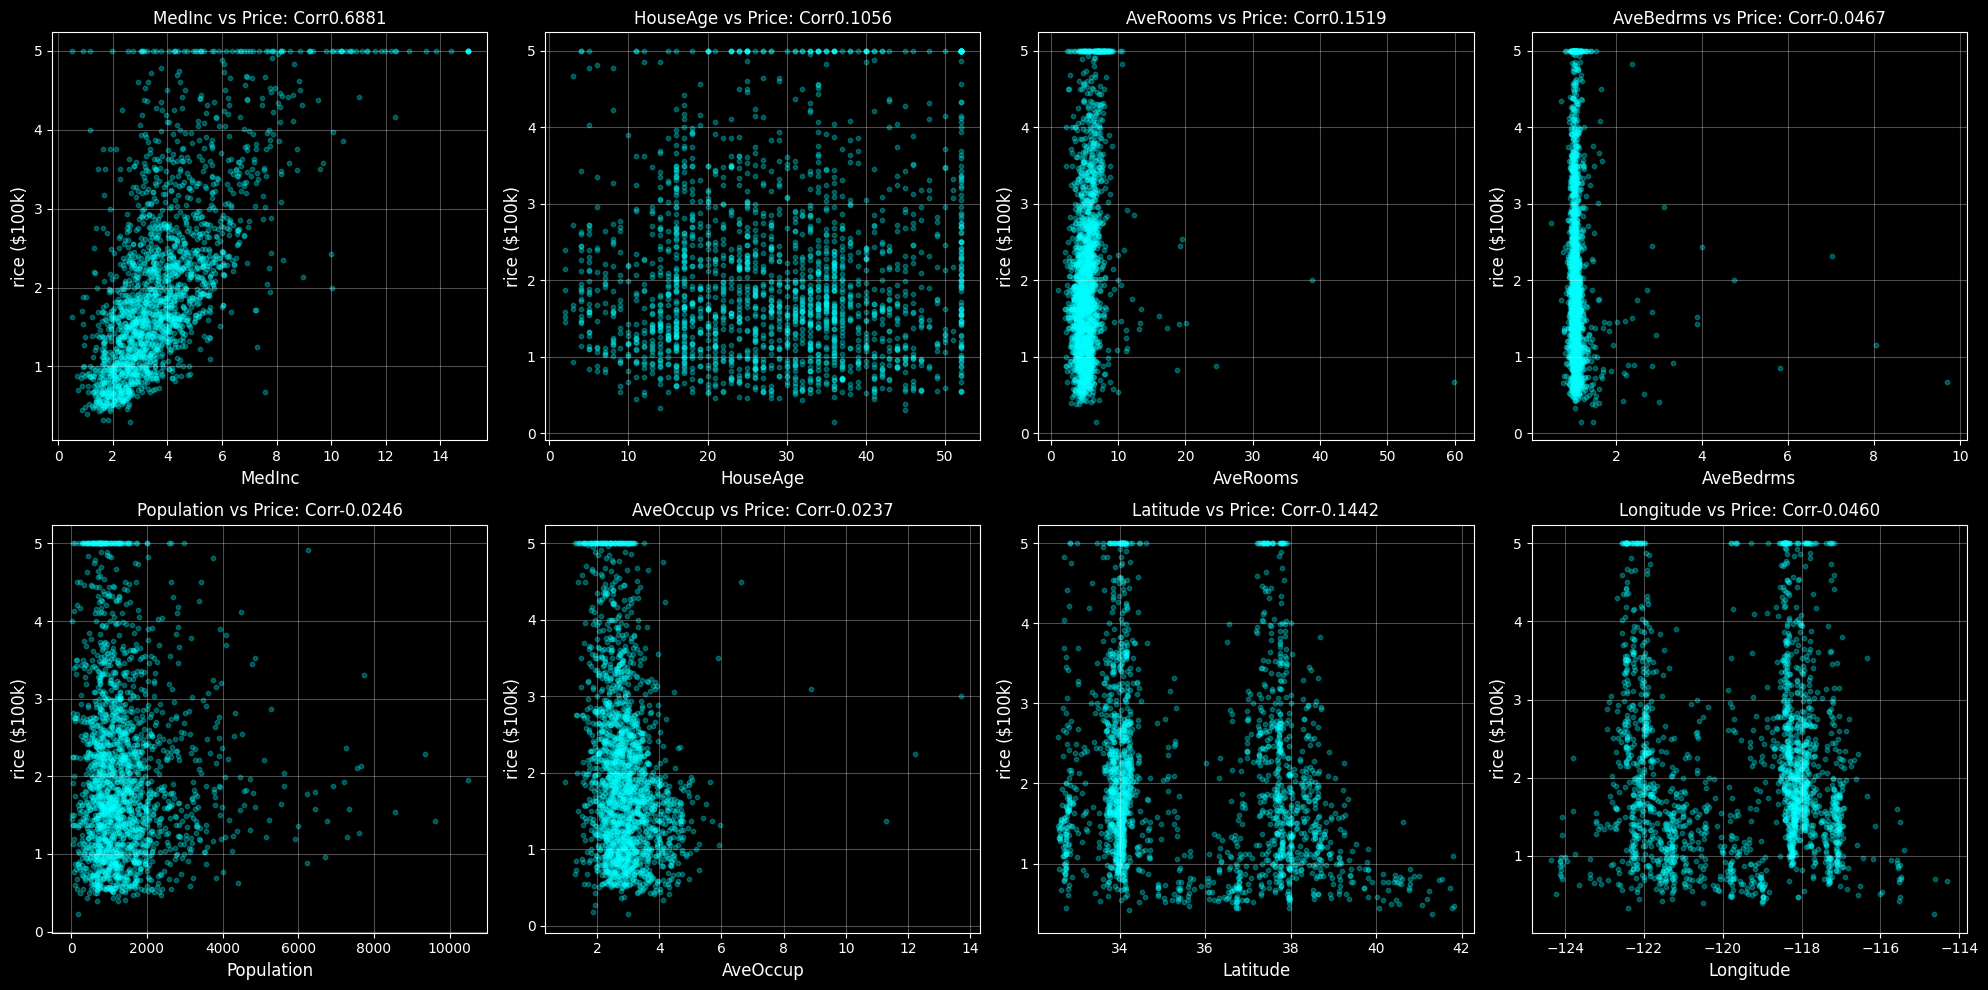

In [42]:
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()

for i, (ax, name) in enumerate(zip(axes, feature_names)):
    indices = np.random.choice(X.shape[0], 2000, replace=False)
    
    ax.scatter(X[indices, i], y[indices], alpha=0.3, s=10, c="cyan")
    ax.set_xlabel(name, fontsize=12)
    ax.set_ylabel("rice ($100k)", fontsize=12)
    ax.set_title(f"{name} vs Price: Corr{correlations[i]:.4f}")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

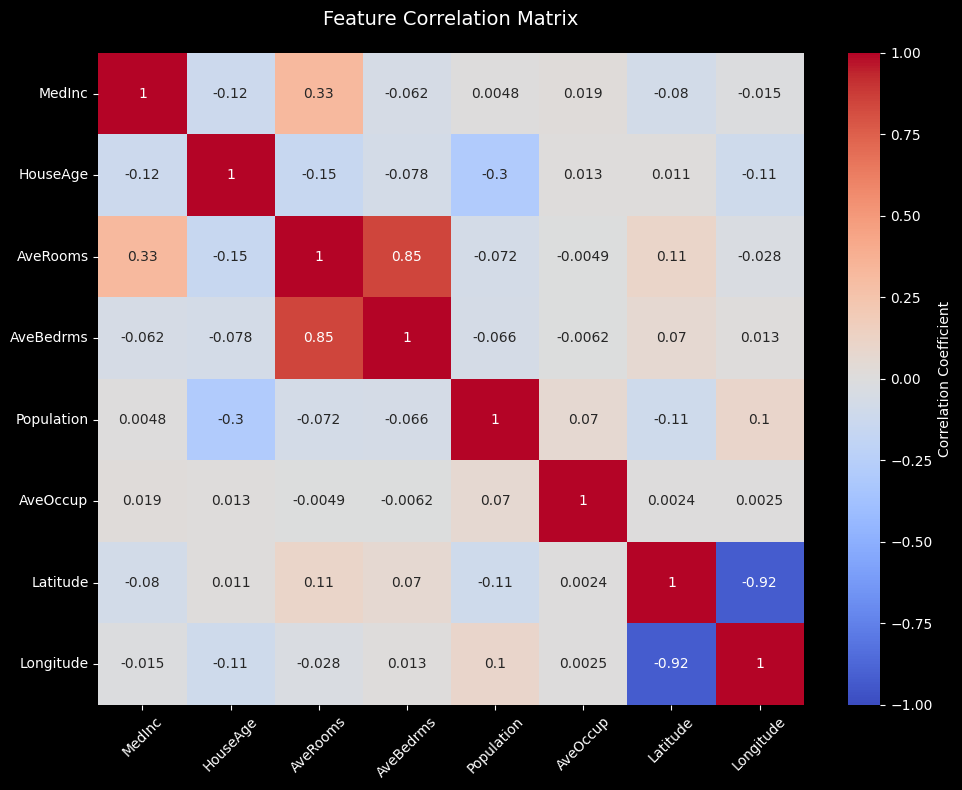

In [43]:
plt.figure(figsize=(10, 8))
sns.heatmap(data.drop("MedHouseVal", axis=1).corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1, cbar_kws={"label": "Correlation Coefficient"})
plt.yticks(rotation=0)
plt.xticks(rotation=45)
plt.title("Feature Correlation Matrix", fontsize=14, pad=20)
plt.tight_layout()
plt.show()

---

## Part 3: Linear Regression from Scratch

Now let's build **linear regression** exactly like you saw in **Lecture 3**!

We'll use **MedInc** (median income) as our feature since it has the strongest correlation.

**Remember from Lecture 3:**
- Model: `ŷ = w * x + b`
- Cost function (MSE): `J = (1/2m) * Σ(ŷ - y)²`
- Gradient descent updates:
  - `w = w - η * (1/m) * Σ(ŷ - y) * x`
  - `b = b - η * (1/m) * Σ(ŷ - y)`

This is **NOT OOP-based** - just simple, clear code using **loops** (Week 1) and **vectorization** (Week 2) .. so that we see the functionality in a simpler way!

In [125]:
X_medinc = X[:, 0]
y_price = y

print(f"Training Samples: {len(X_medinc)}")
print(f"Feature: {feature_names[0]}")
print(f"Target: Median House Value")

Training Samples: 20640
Feature: MedInc
Target: Median House Value


In [120]:
np.random.seed(42)
epochs = 10000
learning_rate = 0.01
n_samples = X.shape[0]

W = np.random.rand()
bias = np.random.rand()

cost_history = []

for i in range(epochs):
    y_hat = (W * X_medinc) + bias
    
    error = y_hat - y

    w_gradient = np.mean(error.T * X_medinc)
    b_gradient = np.mean(error) 
    
    W -= learning_rate * w_gradient
    bias -= learning_rate * b_gradient
    
    mse = 0.5 * np.mean(error**2)
    cost_history.append(mse)
    
    if (i + 1) % 1000 == 0 or i == 0:
        print(f"Epoch {i + 1} : {mse:.5f}")

print("\nTrining Completed!")
print(f"Final W: {W:.4f}")
print(f"Final b: {bias:.4f}")
print(f"Final MSE: {mse:.4f}")


Epoch 1 : 0.40904
Epoch 1000 : 0.35112
Epoch 2000 : 0.35058
Epoch 3000 : 0.35057
Epoch 4000 : 0.35057
Epoch 5000 : 0.35057
Epoch 6000 : 0.35057
Epoch 7000 : 0.35057
Epoch 8000 : 0.35057
Epoch 9000 : 0.35057
Epoch 10000 : 0.35057

Trining Completed!
Final W: 0.4179
Final b: 0.4509
Final MSE: 0.3506


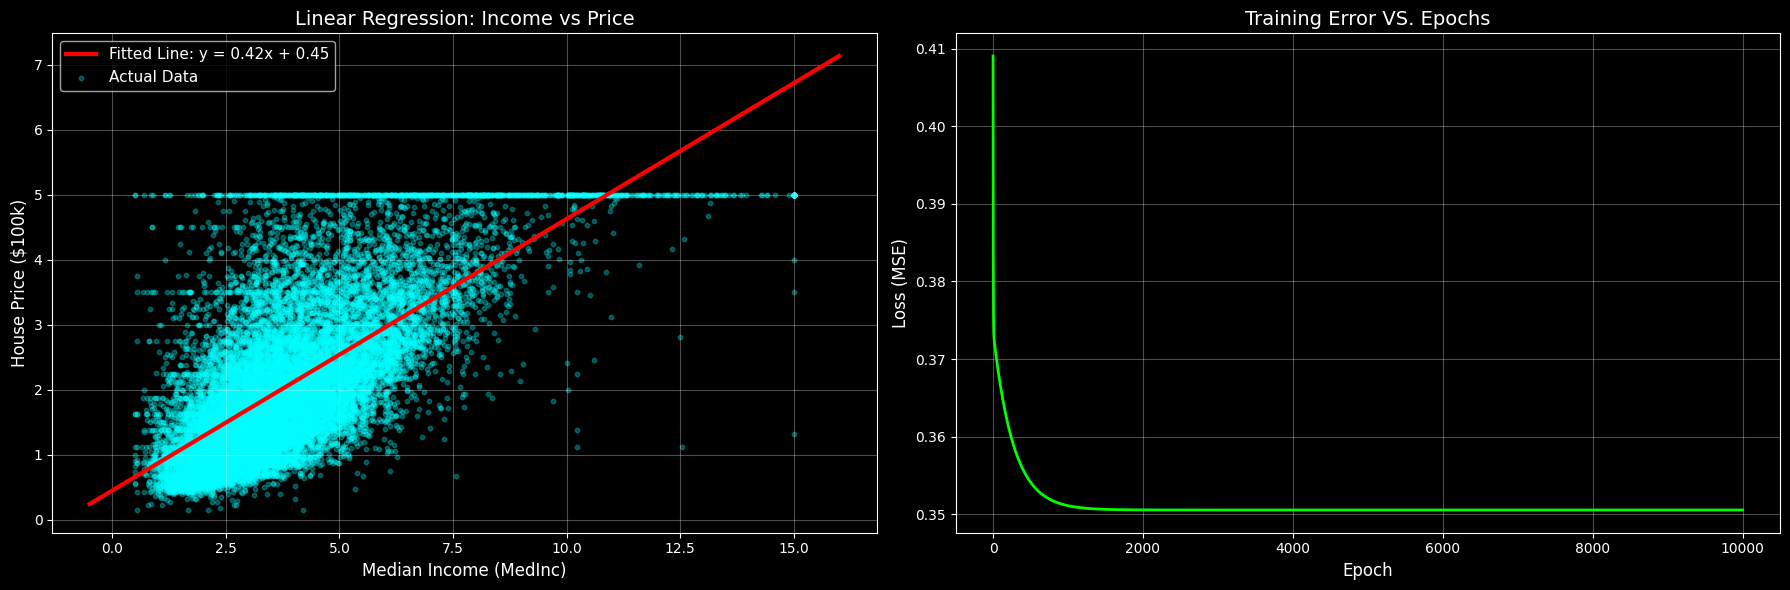

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Plot 1: Data and Fitted Line
ax1 = axes[0]

x_min = np.min(X_medinc) - 1
x_max = np.max(X_medinc) + 1

x_line = np.array([x_min, x_max])
y_line = W * x_line + bias

ax1.plot(x_line, y_line, "r-", linewidth=3, label=f"Fitted Line: y = {W:.2f}x + {bias:.2f}")
ax1.scatter(X_medinc, y_price, alpha=0.3, s=10, c="cyan", label="Actual Data")
ax1.set_xlabel('Median Income (MedInc)', fontsize=12)
ax1.set_ylabel('House Price ($100k)', fontsize=12)
ax1.set_title('Linear Regression: Income vs Price', fontsize=14)
ax1.legend(fontsize=11)
ax1.grid(True, alpha=0.3)

# Plot 2: Loss Function | Cost Convergence
ax2 = axes[1]
ax2.plot(cost_history, "lime", linewidth=2)
ax2.set_xlabel("Epoch", fontsize=12)
ax2.set_ylabel("Loss (MSE)", fontsize=12)
ax2.set_title("Training Error VS. Epochs", fontsize=14)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [47]:
test_incomes = np.array([2.0, 4.0, 6.0, 8.0, 10.0])
test_preds = W * test_incomes + bias

print("Predictions on new data:\n")
for income, pred in zip(test_incomes, test_preds):
    print(f"Median Income {income} → Predicted Price {pred*(1e+5):,.0f}")

print("\nInterpretation: For every $10,000 increase in median income, ")
print(f"house price increases by ${W*1e+4:,.0f} on average.")

Predictions on new data:

Median Income 2.0 → Predicted Price 128,673
Median Income 4.0 → Predicted Price 212,261
Median Income 6.0 → Predicted Price 295,849
Median Income 8.0 → Predicted Price 379,436
Median Income 10.0 → Predicted Price 463,024

Interpretation: For every $10,000 increase in median income, 
house price increases by $4,179 on average.


**What Just Happened?**

1. We initialized random `w` and `b` (weights and bias)
2. Used a **loop** (Week 1) to iterate through 1000 epochs
3. Used **vectorization** (Week 2) for fast gradient calculations
4. Updated weights using gradient descent (Lecture 3 formula)
5. Cost decreased - our model learned!

This is what happens inside important Machine and Deep learning libraries like TensorFlow and PyTorch!

---

## Part 4: Polynomial Regression

In **Lecture 3**, you learned about **polynomial regression** - fitting curves instead of straight lines.

**Linear:** `ŷ = w₁x + b`  
**Quadratic:** `ŷ = w₂x² + w₁x + b`  
**Cubic:** `ŷ = w₃x³ + w₂x² + w₁x + b`

Let's see if a polynomial fits better than a line!

In [48]:
def create_polynomial_features(x, degree):
    """
    Create polynomial features up to specified degree.
    """
    n_samples = len(x)
    X_poly = np.zeros((n_samples, degree))
    
    for i in range(1, degree + 1):
        X_poly[:, i-1] = x ** i
    
    return X_poly

test_x = np.array([1, 2, 3])
test_poly = create_polynomial_features(test_x, degree=2)

print("Polynomial Features:")
print(test_poly)
print("\nColumns: [x, x²]")

Polynomial Features:
[[1. 1.]
 [2. 4.]
 [3. 9.]]

Columns: [x, x²]


In [49]:
def train_polynomial_regression(x, y, degree, learning_rate, epochs):
    x = create_polynomial_features(x, degree)
    
    n_samples = len(x)
    n_features = degree
    
    W = np.zeros(n_features)
    bias = np.random.rand()
    
    loss_history = []
    
    for epoch in range(epochs):
        y_hat = np.dot(x, W) + bias
        
        error = y_hat - y
        
        w_grad = (1 / n_samples) * np.dot(x.T, error)
        b_grad = np.mean(error)
        
        W -= learning_rate * w_grad
        bias -= learning_rate * b_grad
        
        mse = 0.5 * np.mean(error**2)
        loss_history.append(mse)
        
        if (epoch + 1) % 1000 == 0 or epoch == 0:
            print(f"Epoch {epoch + 1} | Loss {mse:.4f}")
    
    return W, bias, mse, loss_history

model = train_polynomial_regression(X_medinc, y_price, 2, 0.001, 10000)

weights = model[0]
bias = model[1]
loss_history = model[3]

print()
print(f"Final Weight 1: {weights[0]:.4f}")
print(f"Final Weight 2: {weights[1]:.4f}")
print(f"Final Bias: {bias:.4f}")
print(f"Final MSE: {model[2]:.4f}")

Epoch 1 | Loss 1.5590
Epoch 1000 | Loss 0.3596
Epoch 2000 | Loss 0.3582
Epoch 3000 | Loss 0.3570
Epoch 4000 | Loss 0.3560
Epoch 5000 | Loss 0.3551
Epoch 6000 | Loss 0.3543
Epoch 7000 | Loss 0.3535
Epoch 8000 | Loss 0.3529
Epoch 9000 | Loss 0.3523
Epoch 10000 | Loss 0.3518

Final Weight 1: 0.3952
Final Weight 2: -0.0002
Final Bias: 0.5623
Final MSE: 0.3518


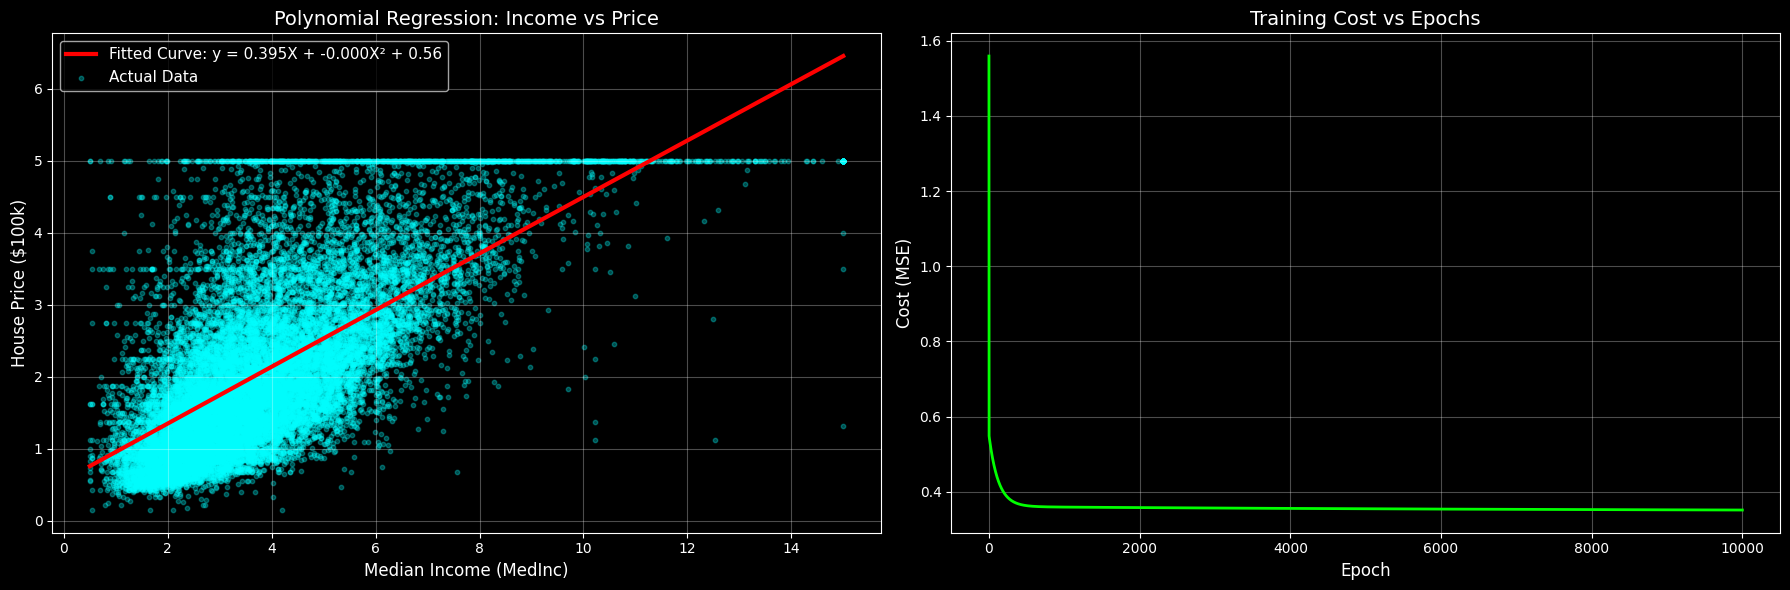

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Plot 1: Fitted Curve
ax1 = axes[0]

weight1 = weights[0]
weight2 = weights[1]
x_line = np.linspace(X_medinc.min(), X_medinc.max(), 1000)
y_line = (weight1 * x_line) + (weight2 * (x_line**2)) + bias

ax1.plot(x_line, y_line, "r-", linewidth=3, label=f"Fitted Curve: y = {weight1:.3f}X + {weight2:.3f}X² + {bias:.2f}")
ax1.scatter(X_medinc, y_price, c="cyan", label="Actual Data", alpha=0.3, s=10)
ax1.set_xlabel('Median Income (MedInc)', fontsize=12)
ax1.set_ylabel('House Price ($100k)', fontsize=12)
ax1.set_title('Polynomial Regression: Income vs Price', fontsize=14)
ax1.legend(fontsize=11)
ax1.grid(True, alpha=0.3)

# Plot 2: Cont Convergence
ax2 = axes[1]
ax2.plot(loss_history, c="lime", linewidth=2)
ax2.set_xlabel('Epoch', fontsize=12)
ax2.set_ylabel('Cost (MSE)', fontsize=12)
ax2.set_title('Training Cost vs Epochs', fontsize=14)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [51]:
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import PolynomialFeatures

def train_polynomial_regression_sklearn(x, y, degree, epochs):
    """
    Train polynomial regression using sklearn's PolynomialFeatures + LinearRegression.
    We track loss history for visualization purposes.
    """
    poly = PolynomialFeatures(degree=degree)
    X_poly = poly.fit_transform(x.reshape(-1, 1))
    
    model = LinearRegression()
    model.fit(X_poly, y)
    
    y_pred = model.predict(X_poly)
    mse = 0.5 * mean_squared_error(y, y_pred)
    
    loss = [mse] * epochs
    
    return model.coef_, loss, X_poly

print("Polynomial regression function ready (using Sklearn)!")

Polynomial regression function ready (using Sklearn)!


In [52]:
degrees = [1, 2, 3, 5]
models = {}

for degree in degrees:
    model = train_polynomial_regression_sklearn(X_medinc, y_price, degree=degree, epochs=500)
    
    weights = model[0]
    losses = model[1]
    
    models[degree] = (weights, losses)
    print(f"Degree {degree}: Final MSE = {losses[-1]:.4f}")

Degree 1: Final MSE = 0.3506
Degree 2: Final MSE = 0.3475
Degree 3: Final MSE = 0.3421
Degree 5: Final MSE = 0.3420


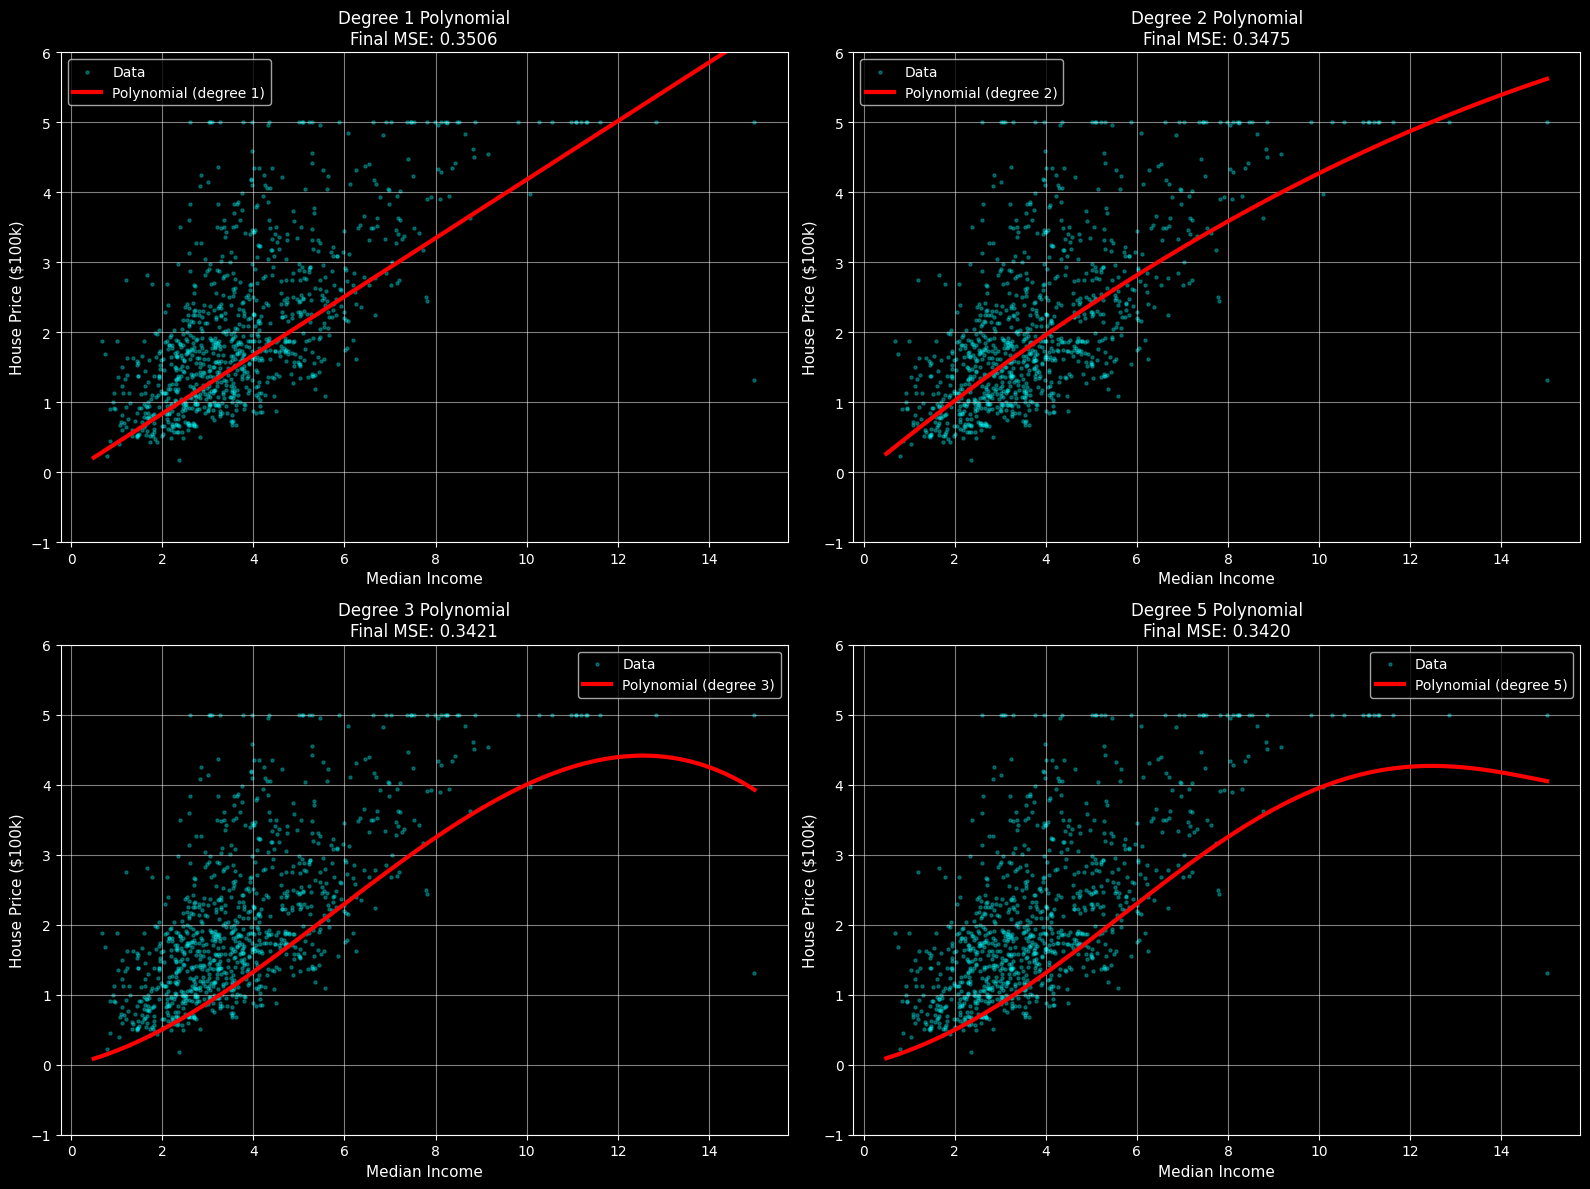

In [53]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

indices = np.random.choice(len(X_medinc), 1000, replace=False)
x_plot = np.linspace(X_medinc.min(), X_medinc.max(), 200)

for ax, degree in zip(axes, degrees):
    ax.scatter(X_medinc[indices], y_price[indices], alpha=0.3, c="cyan", s=5, label="Data")
    
    weights = models[degree][0]
    poly = PolynomialFeatures(degree=degree, include_bias=True)
    X_plot_poly = poly.fit_transform(x_plot.reshape(-1, 1))
    y_plot = X_plot_poly @ weights
    
    ax.plot(x_plot, y_plot, "r-", linewidth=3, label=f"Polynomial (degree {degree})")
    ax.set_xlabel('Median Income', fontsize=11)
    ax.set_ylabel('House Price ($100k)', fontsize=11)
    ax.set_title(f"Degree {degree} Polynomial\nFinal MSE: {models[degree][1][-1]:.4f}", fontsize=12)
    ax.legend()
    ax.grid(True, alpha=0.5)
    ax.set_ylim([-1, 6])

plt.tight_layout()
plt.show()

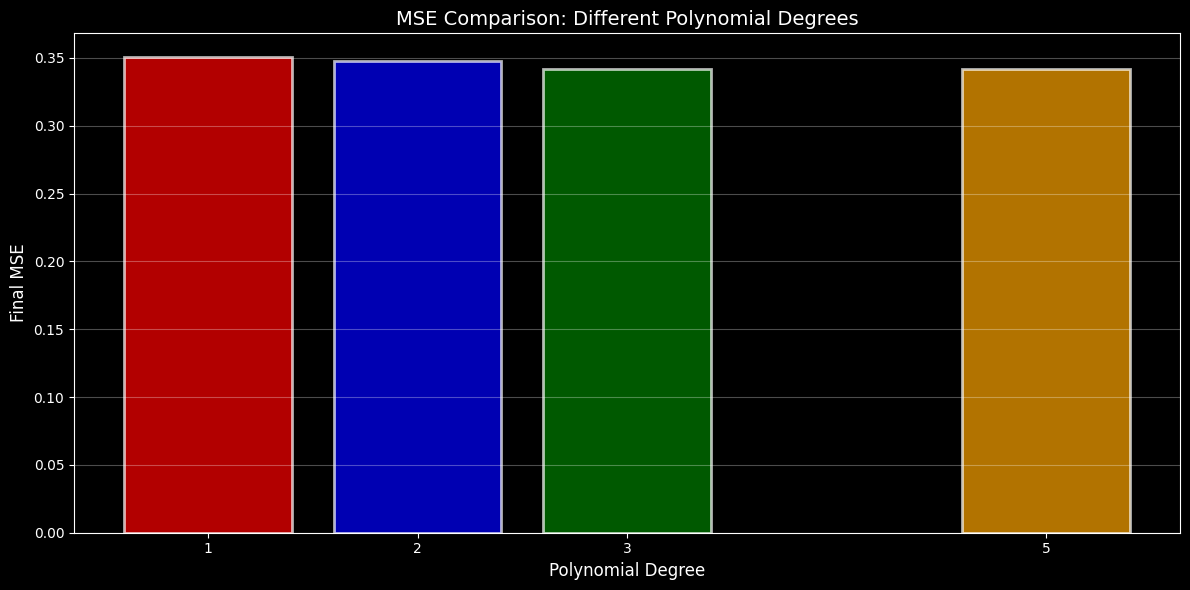

In [54]:
degrees_list = list(degrees)
mse_values = [models[degree][1][-1] for degree in degrees]

plt.figure(figsize=(12, 6))
plt.bar(degrees_list, mse_values, color=["red", "blue", "green", "orange"], alpha=0.7, edgecolor="white", linewidth=2)

plt.xlabel("Polynomial Degree", fontsize=12)
plt.ylabel("Final MSE", fontsize=12)
plt.title('MSE Comparison: Different Polynomial Degrees', fontsize=14)
plt.xticks(degrees_list)
plt.grid(True, alpha=0.3, axis="y")
plt.tight_layout()
plt.show()

---
## Part 5: Comparing Optimizers

In [55]:
n_samples = 5000
X_train = X[:n_samples, 0].reshape(-1, 1)
y_train = y[:n_samples]

print(f"Training wiht {n_samples} samples")
print(f"Feature Name: {feature_names[0]}")
print(f"\nWe'll compare 6 different optimizers!")

Training wiht 5000 samples
Feature Name: MedInc

We'll compare 6 different optimizers!


In [56]:
def batch_gradient_descent(X, y, learning_rate, epochs):
    """
    Standard Batch Gradient Descent.
    Uses all samples in each iteration.
    """
    n_samples = len(X)
    np.random.seed(42)
    
    w = 0.5
    b = 0.5
    
    loss_history = []
    w_hist = [w]
    b_hist = [b]
    
    for epoch in range(epochs):
        y_pred = (w * X.flatten()) + b
        
        error = y_pred - y
        
        grad_w = np.mean(error * X.flatten())
        grad_b = np.mean(error)
        
        w -= learning_rate * grad_w
        b -= learning_rate * grad_b
        
        loss = 0.5 * np.mean(error**2)
        loss_history.append(loss)
        w_hist.append(w)
        b_hist.append(b)
        
    return loss_history, np.array(w_hist), np.array(b_hist)

print("Batch Gradient Descent function ready!")

Batch Gradient Descent function ready!


In [57]:
import torch
import torch.nn as nn
import torch.optim as optim

X_train_torch = torch.FloatTensor(X_train)
y_train_torch = torch.FloatTensor(y_train)

max_iter = 200
results = {}

print("Start Training...\n")

def create_model():
    torch.manual_seed(42)
    model = nn.Linear(1, 1)

    # Initialize wiht same values for fair comparison
    nn.init.constant_(model.weight, 0.5)
    nn.init.constant_(model.bias, 0.5)
    return model

def custom_loss_function(output, target):
    error = output - target
    mse = 0.5 * torch.mean(error**2)
    return mse

Start Training...



In [58]:
# 1. Batch Gradient Descent (from scratch - reference)
print("1. Batch Gradient Descent (from scratch)...")
costs_batch, w_batch, b_batch = batch_gradient_descent(X_train, y_train, learning_rate=0.01, epochs=max_iter)

w_batch_3d = w_batch
b_batch_3d = b_batch

results["Batch GD"] = costs_batch
print(f"Final MSE: {costs_batch[-1]:.4f}")

1. Batch Gradient Descent (from scratch)...
Final MSE: 0.3159


In [59]:
# 2. SGD (Stochastic Gradient Descent)
print("\n2. Stochastic Gradient Descent (SGD)...")
model_sgd = create_model()

optimizer_sgd = optim.SGD(model_sgd.parameters(), lr=0.01)
loss_sgd = []
w_history_sgd = [0.5]
b_history_sgd = [0.5]

for epoch in range(max_iter):
    optimizer_sgd.zero_grad()
    outputs = model_sgd(X_train_torch)
    loss = custom_loss_function(outputs.squeeze(), y_train_torch)
    loss.backward()
    optimizer_sgd.step()
    
    loss_sgd.append(loss.item())
    w_history_sgd.append(model_sgd.weight.item())
    b_history_sgd.append(model_sgd.bias.item())

results["SGD"] = loss_sgd
print(f"Final MSE: {loss_sgd[-1]:.4f}")


2. Stochastic Gradient Descent (SGD)...
Final MSE: 0.3159


In [60]:
# SDG with Momentum
print("\n3. SGD with Momentum...")
model_momentum = create_model()

sgd_momentum = optim.SGD(model_momentum.parameters(), lr=0.01, momentum=0.9)
w_history_sgd_mom = [0.5]
b_history_sgd_mom = [0.5]
loss_sgd_mom = []

for epoch in range(max_iter):
    sgd_momentum.zero_grad()
    outputs = model_momentum(X_train_torch)
    loss = custom_loss_function(outputs.squeeze(), y_train_torch)
    loss.backward()
    sgd_momentum.step()
    
    loss_sgd_mom.append(loss.item())
    w_history_sgd_mom.append(model_momentum.weight.item())
    b_history_sgd_mom.append(model_momentum.bias.item())

results["Momentum"] = loss_sgd_mom
print(f"Final MSE: {loss_sgd_mom[-1]:.4f}")


3. SGD with Momentum...
Final MSE: 0.3157


In [61]:
# 4. RMSProb (Root Mean Square Propagation)
print("\n4. RMSprop...")
model_rmsprop = create_model()

rms_optimizer = optim.RMSprop(model_rmsprop.parameters(), lr=0.01)
w_history_rmsp = [0.5]
b_history_rmsp = [0.5]
loss_rmsp = []

for epoch in range(max_iter):
    rms_optimizer.zero_grad()
    outputs = model_rmsprop(X_train_torch)
    loss = custom_loss_function(outputs.squeeze(), y_train_torch)
    loss.backward()
    rms_optimizer.step()
    
    loss_rmsp.append(loss.item())
    w_history_rmsp.append(model_rmsprop.weight.item())
    b_history_rmsp.append(model_rmsprop.bias.item())

results["RMSProp"] = loss_rmsp
print(f"Final MSE: {loss_rmsp[-1]:.4f}")


4. RMSprop...
Final MSE: 0.3157


In [62]:
# 5. Adam (Adaptive Moment Estimation) 
print("\n5. Adam...")
model_adam = create_model()

adam_optimizer = optim.Adam(model_adam.parameters(), lr=0.01)
w_history_adam = [0.5]
b_history_adam = [0.5]
loss_adam = []

for epoch in range(max_iter):
    adam_optimizer.zero_grad()
    outputs = model_adam(X_train_torch)
    loss = custom_loss_function(outputs.squeeze(), y_train_torch)
    loss.backward()
    adam_optimizer.step()
    
    loss_adam.append(loss.item())
    w_history_adam.append(model_adam.weight.item())
    b_history_adam.append(model_adam.bias.item())

results["Adam"] = loss_adam
print(f"Final MSE: {loss_adam[-1]:.4f}")


5. Adam...
Final MSE: 0.3157


In [68]:
# 6. AdamW (Adam with weight decay) 
print("\n6. AdamW...")
model_adamw = create_model()

adamw_optimizer = optim.AdamW(model_adamw.parameters(), lr=0.01)
w_history_adamw = [0.5]
b_history_adamw = [0.5]
loss_adamw = []

for epoch in range(max_iter):
    adamw_optimizer.zero_grad()
    outputs = model_adamw(X_train_torch)
    loss = custom_loss_function(outputs.squeeze(), y_train_torch)
    loss.backward()
    adamw_optimizer.step()
    
    loss_adamw.append(loss.item())
    w_history_adamw.append(model_adamw.weight.item())
    b_history_adamw.append(model_adamw.bias.item())

results["AdamW"] = loss_adamw
print(f"Final MSE: {loss_adamw[-1]:.4f}")


6. AdamW...
Final MSE: 0.3157


In [69]:
# 7. AdaGrad (Adabtive Gradient Descent)
print("\n7. AdaGrad...")
model_adagrad = create_model()

adagrad_optimizer = optim.Adagrad(model_adagrad.parameters(), lr=0.01)
w_history_adagrad = [0.5]
b_history_adagrad = [0.5]
loss_adagrad = []

for epoch in range(max_iter):
    adagrad_optimizer.zero_grad()
    outputs = model_adagrad(X_train_torch)
    loss = custom_loss_function(outputs.squeeze(), y_train_torch)
    loss.backward()
    adagrad_optimizer.step()
    
    loss_adagrad.append(loss.item())
    w_history_adagrad.append(model_adagrad.weight.item())
    b_history_adagrad.append(model_adagrad.bias.item())

results["AdaGrad"] = loss_adagrad
print(f"Final MSE: {loss_adagrad[-1]:.4f}")


7. AdaGrad...


Final MSE: 0.3157


In [70]:
weight_histories = {
    "Batch GD": (w_batch_3d, b_batch_3d) if "w_batch_3d" in locals() else (None, None),
    "SGD": (np.array(w_history_sgd), np.array(b_history_sgd)),
    "Momentum": (np.array(w_history_sgd_mom), np.array(b_history_sgd_mom)),
    "RMSProb": (np.array(w_history_rmsp), np.array(b_history_rmsp)),
    "Adam": (np.array(w_history_adam), np.array(b_history_adam)),
    "AdamW": (np.array(w_history_adamw), np.array(b_history_adamw)),
    "AdaGrad": (np.array(w_history_adagrad), np.array(b_history_adagrad)),
}

Creating 3D loss surface visualization...


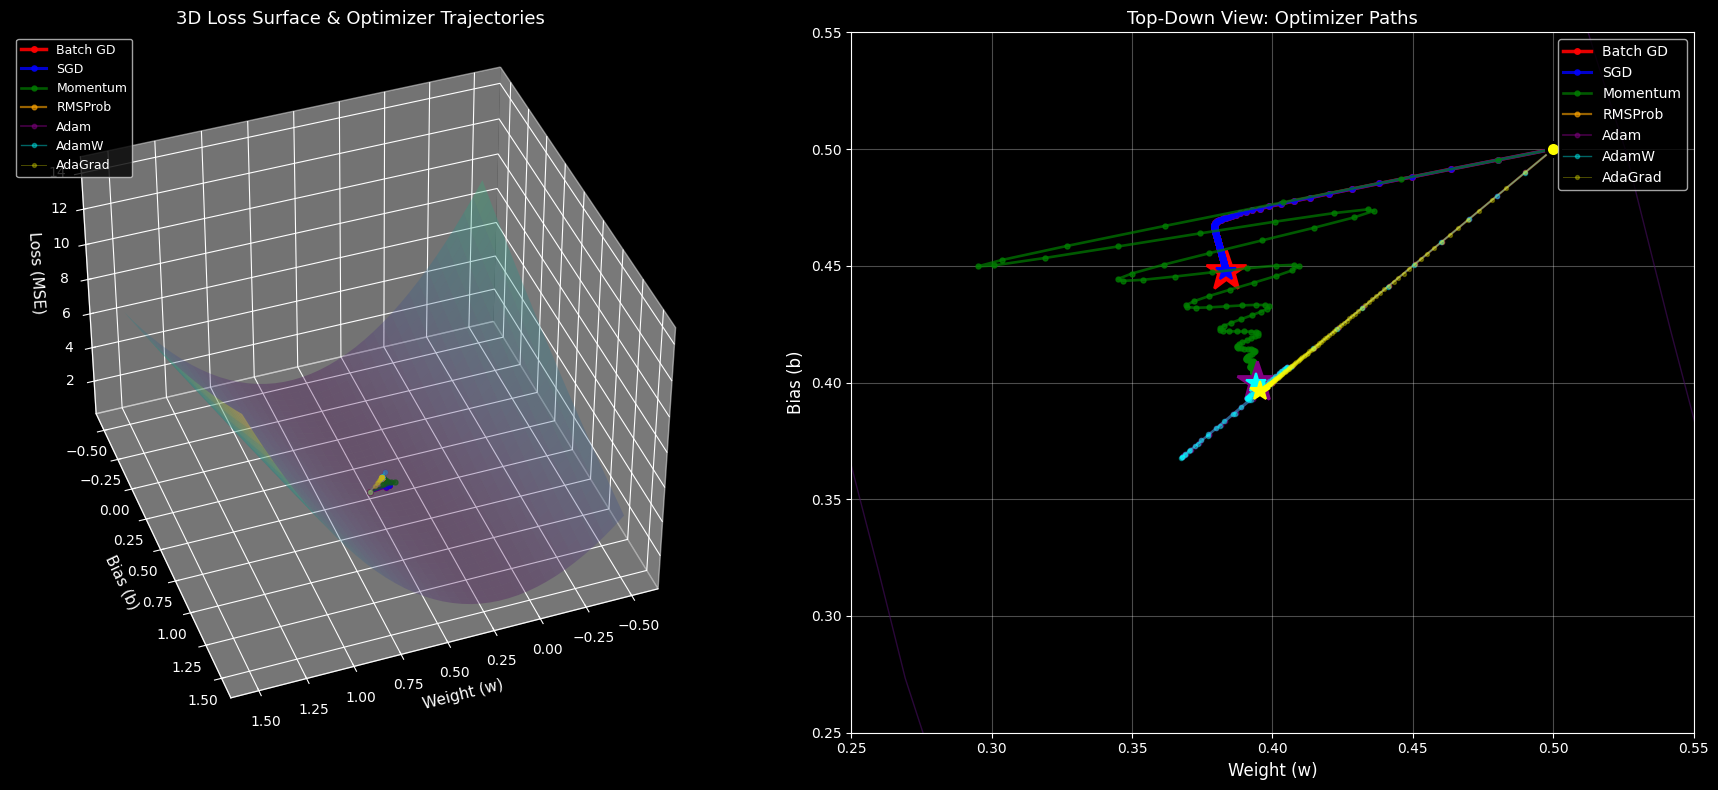

In [72]:
print("Creating 3D loss surface visualization...")

fig = plt.figure(figsize=(18, 8))

# Subplot 1: 3D Loss surface wiht paths
ax1 = fig.add_subplot(121, projection="3d")

# Create grid for loss surface
w_range = np.linspace(-0.5, 1.5, 40)
b_range = np.linspace(-0.5, 1.5, 40)
W, B = np.meshgrid(w_range, b_range)

# Calculate loss for each point on the grid
Z = np.zeros_like(W)
X_flat = X_train.flatten()
for i in range(W.shape[0]):
    for j in range(W.shape[1]):
        y_pred = W[i, j] * X_flat + B[i, j]
        Z[i, j] = 0.5 * np.mean((y_pred - y_train)**2)

surf = ax1.plot_surface(W, B, Z, alpha=0.3, cmap="viridis", edgecolor="none")

colors_3d = ["red", "blue", "green", "orange", "purple", "cyan", "yellow"]
optimizer_names = ["Batch GD", "SGD", "Momentum", "RMSProb", "Adam", "AdamW", "AdaGrad"]

for i, (name, color) in enumerate(zip(optimizer_names, colors_3d)):
    if name in weight_histories and weight_histories[name][0] is not None:
        w_hist, b_hist = weight_histories[name]
        
        z_hist = []
        for w, b in zip(w_hist, b_hist):
            y_pred = w * X_flat + b
            z = 0.5 * np.mean((y_pred - y_train)**2)
            z_hist.append(z)
        
        step = max(1, len(w_hist) // 20)
        linewidth = 2.5 - 0.3 * i
        markersize = 4 - 0.2 * i
        alpha = 0.9 - 0.1 * i
        
        ax1.plot(w_hist[::step], b_hist[::step], z_hist[::step], color=color, linewidth=linewidth, marker="o", markersize=markersize, label=name, alpha=alpha)

ax1.set_xlabel('Weight (w)', fontsize=11)
ax1.set_ylabel('Bias (b)', fontsize=11)
ax1.set_zlabel('Loss (MSE)', fontsize=11)
ax1.set_title('3D Loss Surface & Optimizer Trajectories', fontsize=13)
ax1.legend(fontsize=9, loc="upper left")
ax1.view_init(elev=40, azim=70)

# Subplot 2: Top-down contour view
ax2 = fig.add_subplot(122)

contour = ax2.contour(W, B, Z, levels=30, cmap="viridis", alpha=0.6, linewidths=1)
ax2.clabel(contour, inline=True, fontsize=8, fmt="%.2f")

for i, (name, color) in enumerate(zip(optimizer_names, colors_3d)):
    if name in weight_histories and weight_histories[name][0] is not None:
        w_hist, b_hist = weight_histories[name]
        
        linewidth = 2.5 - 0.3 * i
        markersize = 4 - 0.2 * i
        alpha = 0.9 - 0.1 * i
        
        ax2.plot(w_hist, b_hist, color=color, linewidth=linewidth, marker="o", markersize=markersize, label=name, alpha=alpha)
        
        if name != "Batch GD" and name != "Adam":
            ax2.plot(w_hist[0], b_hist[0], "ko", markersize=10, markerfacecolor=color, markeredgewidth=2)
        
        if name == "Batch GD" or name == "Adam":
            ax2.plot(w_hist[-1], b_hist[-1], color=color, marker="*", markersize=30, markerfacecolor=color, markeredgewidth=2)
        
        else:
            ax2.plot(w_hist[-1], b_hist[-1], color=color, marker="*", markersize=15, markerfacecolor=color, markeredgewidth=1.5)

ax2.set_xlabel('Weight (w)', fontsize=12)
ax2.set_ylabel('Bias (b)', fontsize=12)
ax2.set_title('Top-Down View: Optimizer Paths', fontsize=13)
ax2.legend(fontsize=10, loc='upper right')
ax2.grid(True, alpha=0.3)

ax2.set_xlim([0.25, 0.55])
ax2.set_ylim([0.25, 0.55])

plt.tight_layout()
plt.show()

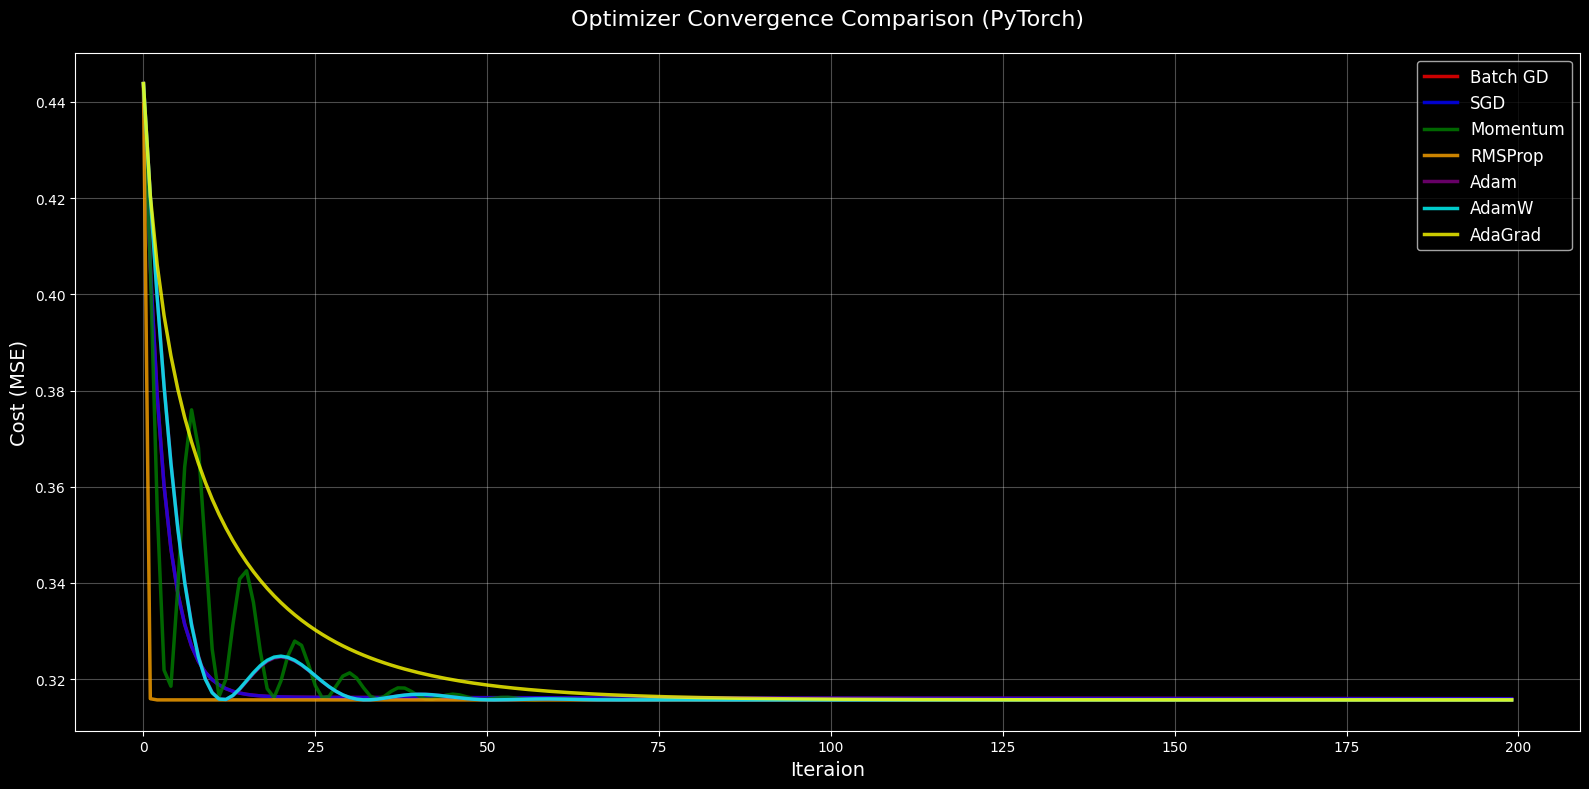

In [73]:
plt.figure(figsize=(16, 8))

colors = ['red', 'blue', 'green', 'orange', 'purple', 'cyan', "yellow"]
for (name, losses), color in zip(results.items(), colors):
    plt.plot(losses, linewidth=2.5, label=name, color=color, alpha=0.8)

plt.xlabel("Iteraion", fontsize=14)
plt.ylabel("Cost (MSE)", fontsize=14)
plt.title("Optimizer Convergence Comparison (PyTorch)", fontsize=16, pad=20)
plt.legend(fontsize=12, loc="upper right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

---

## Part 6: sklearn LinearRegression


Let's compare our from-scratch version with sklearn!

In [74]:
# Use sklearn's LinearRegression
from sklearn.linear_model import LinearRegression

# Train the model
sklearn_model = LinearRegression()
sklearn_model.fit(X_train, y_train)

# Extract learned parameters
w_sklearn = sklearn_model.coef_[0]
b_sklearn = sklearn_model.intercept_

print("sklearn LinearRegression trained!")
print(f"\nLearned parameters:")
print(f"  Weight (w): {w_sklearn:.4f}")
print(f"  Bias (b):   {b_sklearn:.4f}")

sklearn LinearRegression trained!

Learned parameters:
  Weight (w): 0.3943
  Bias (b):   0.4001


In [75]:
# Compare with our from-scratch model (from Part 5)
print("\n" + "="*50)
print("COMPARISON: From-Scratch vs sklearn")
print("="*50)

# Our from-scratch model (Batch GD from Part 5)
# w_batch and b_batch are already scalars from cell 29
print(f"\nFrom-Scratch (Batch GD):")
print(f"  Final MSE:  {costs_batch[-1]}")

# sklearn model
y_pred_sklearn = sklearn_model.predict(X_train)
mse_sklearn = 0.5 * np.mean((y_pred_sklearn - y_train)**2)

print(f"\nsklearn LinearRegression:")
print(f"  Final MSE:  {mse_sklearn}")

print(f"\nDifference:")
print(f"  MSE difference:    {abs(costs_batch[-1] - mse_sklearn)}")

print("\nConclusion: Both methods produce nearly identical results!")
print("sklearn uses the Normal Equation (instant, no iteration needed).")


COMPARISON: From-Scratch vs sklearn

From-Scratch (Batch GD):
  Final MSE:  0.31592672361645446

sklearn LinearRegression:
  Final MSE:  0.3156783243855424

Difference:
  MSE difference:    0.0002483992309120775

Conclusion: Both methods produce nearly identical results!
sklearn uses the Normal Equation (instant, no iteration needed).


In [115]:
# Extract HouseAge feature
x_houseage = X[:, 1]
y_price_ex1 = y

np.random.seed(42)
w_ex1 = np.random.rand()
b_ex1 = np.random.rand()
lr = 0.001
epochs = 500
cost_history_ex1 = []

for epoch in range(epochs):
    y_hat = (w_ex1 * x_houseage) + b_ex1
    error = y_hat - y_price_ex1

    w_gradient = np.mean(error * x_houseage)
    b_graident = np.mean(error)

    w_ex1 -= lr * w_gradient
    b_ex1 -= lr * b_graident

    loss_error = 0.5 * np.mean(error ** 2)
    cost_history_ex1.append(loss_error)

print(f"Final w: {w_ex1:.4f}")
print(f"Final b: {b_ex1:.4f}")
print(f"Final MSE: {cost_history_ex1[-1]:.4f}")

Final w: 0.0326
Final b: 1.0068
Final MSE: 0.7082


In [105]:
# Tests
### BEGIN HIDDEN TESTS
assert 'w_ex1' in locals(), "Variable w_ex1 not found"
assert 'b_ex1' in locals(), "Variable b_ex1 not found"
assert 'cost_history_ex1' in locals(), "Variable cost_history_ex1 not found"
assert len(cost_history_ex1) > 0, "Cost history is empty"
assert cost_history_ex1[-1] < 1.5, "Final cost is too high - check your implementation"
print("✓ Exercise 1 tests passed!")
### END HIDDEN TESTS

✓ Exercise 1 tests passed!


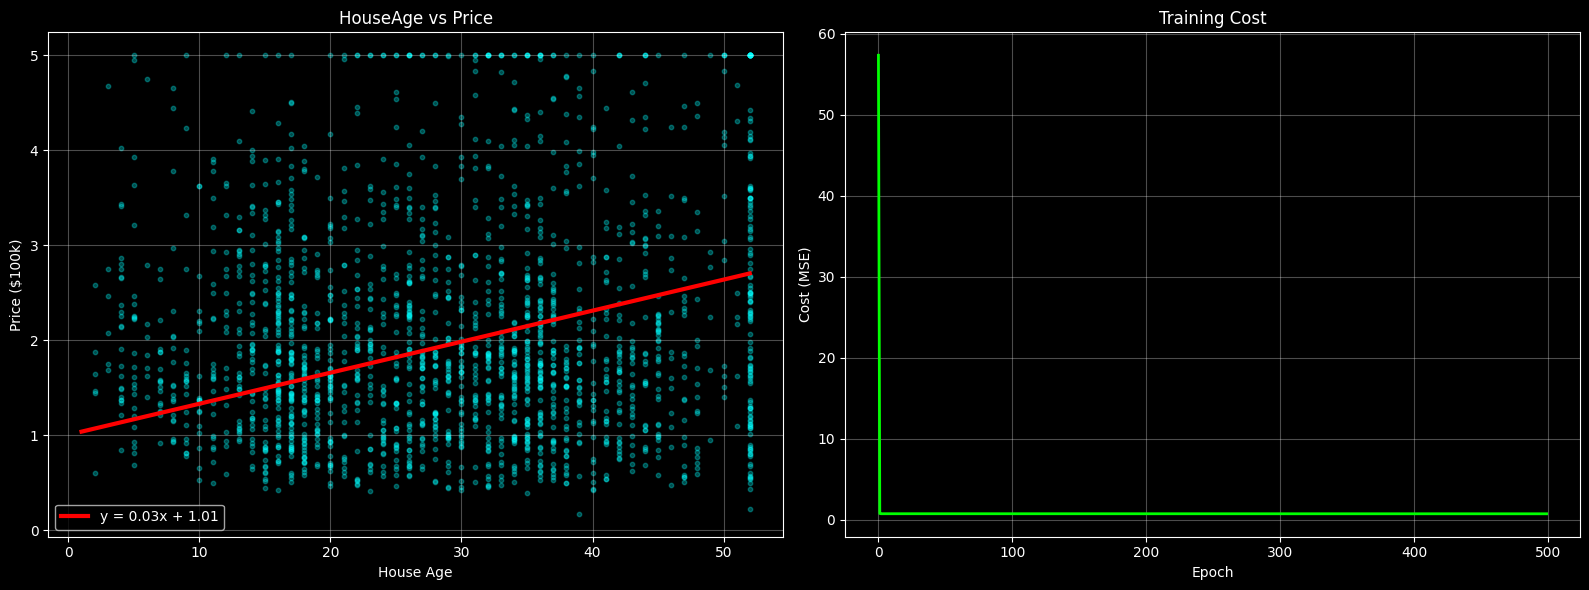


HouseAge has correlation 0.106 with price.
Compare this to MedInc's correlation of 0.688!


In [106]:
# Visualize your results
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Scatter + fitted line
indices = np.random.choice(len(x_houseage), 2000, replace=False)
axes[0].scatter(x_houseage[indices], y_price_ex1[indices], alpha=0.3, s=10, c='cyan')
x_line = np.linspace(x_houseage.min(), x_houseage.max(), 100)
y_line = w_ex1 * x_line + b_ex1
axes[0].plot(x_line, y_line, 'r-', linewidth=3, label=f'y = {w_ex1:.2f}x + {b_ex1:.2f}')
axes[0].set_xlabel('House Age')
axes[0].set_ylabel('Price ($100k)')
axes[0].set_title('HouseAge vs Price')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot 2: Cost curve
axes[1].plot(cost_history_ex1, 'lime', linewidth=2)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Cost (MSE)')
axes[1].set_title('Training Cost')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\nHouseAge has correlation {np.corrcoef(x_houseage, y_price_ex1)[0,1]:.3f} with price.")
print(f"Compare this to MedInc's correlation of {np.corrcoef(X[:, 0], y)[0,1]:.3f}!")

### Exercise 2: Compare Two Features

Train linear regression on **AveRooms** (feature 2) and compare its performance (MSE) to **MedInc** (feature 0).

Which feature gives better predictions?

In [122]:
# Extract HouseAge feature
x_averrooms = X[:, 2]

np.random.seed(42)
w_ex2 = np.random.rand()
b_ex2 = np.random.rand()
lr = 0.001
epochs = 500
cost_history_ex2 = []

for epoch in range(epochs):
    y_hat = (w_ex2 * x_averrooms) + b_ex2
    error = y_hat - y_price_ex1

    w_gradient = np.mean(error * x_averrooms)
    b_graident = np.mean(error)

    w_ex2 -= lr * w_gradient
    b_ex2 -= lr * b_graident

    loss_error = 0.5 * np.mean(error ** 2)
    cost_history_ex2.append(loss_error)

print(f"Final w: {w_ex2:.4f}")
print(f"Final b: {b_ex2:.4f}")

final_mse_averrooms = cost_history_ex2[-1]
final_mse_medinc = cost_history[-1]  # From Part 3

print(f"AveRooms - Final MSE: {final_mse_averrooms:.4f}")
print(f"MedInc   - Final MSE: {final_mse_medinc:.4f}")
print(f"\nBetter feature: {'MedInc' if final_mse_medinc < final_mse_averrooms else 'AveRooms'}")

Final w: 0.1782
Final b: 0.9835
AveRooms - Final MSE: 0.6926
MedInc   - Final MSE: 0.3506

Better feature: MedInc


In [123]:
# Tests
### BEGIN HIDDEN TESTS
assert 'final_mse_averrooms' in locals(), "Variable final_mse_averrooms not found"
assert 'final_mse_medinc' in locals(), "Variable final_mse_medinc not found"
assert final_mse_medinc < final_mse_averrooms, "MedInc should have lower MSE"
print("✓ Exercise 2 tests passed!")
print(f"\nInsight: MedInc is {((final_mse_averrooms/final_mse_medinc - 1)*100):.1f}% better than AveRooms!")
### END HIDDEN TESTS

✓ Exercise 2 tests passed!

Insight: MedInc is 97.6% better than AveRooms!


### Exercise 3: Polynomial Regression Practice

Train a **degree 2** polynomial regression on **MedInc** and compare it to the linear model (degree 1).

Does the polynomial give better results?

In [126]:
# YOUR CODE HERE: Use sklearn polynomial functions from Part 4
### BEGIN SOLUTION
# Train degree 2 polynomial using sklearn
weights_poly2, costs_poly2, _ = train_polynomial_regression_sklearn(
    X_medinc, y_price, degree=2, epochs=500
)

# Compare with linear (degree 1) using sklearn
weights_poly1, costs_poly1, _ = train_polynomial_regression_sklearn(
    X_medinc, y_price, degree=1, epochs=500
)

final_mse_poly1 = costs_poly1[-1]
final_mse_poly2 = costs_poly2[-1]

print(f"Degree 1 (Linear) - Final MSE: {final_mse_poly1:.4f}")
print(f"Degree 2 (Quadratic) - Final MSE: {final_mse_poly2:.4f}")
print(f"\nImprovement: {((final_mse_poly1 - final_mse_poly2)/final_mse_poly1 * 100):.2f}%")

Degree 1 (Linear) - Final MSE: 0.3506
Degree 2 (Quadratic) - Final MSE: 0.3475

Improvement: 0.87%


In [127]:
# Tests
### BEGIN HIDDEN TESTS
assert 'final_mse_poly1' in locals(), "Variable final_mse_poly1 not found"
assert 'final_mse_poly2' in locals(), "Variable final_mse_poly2 not found"
assert final_mse_poly2 < final_mse_poly1, "Degree 2 should have lower MSE"
assert len(weights_poly2) == 3, "Degree 2 should have 3 weights [b, w1, w2]"
print("✓ Exercise 3 tests passed!")
print(f"\nThe quadratic term improved the model by capturing non-linear patterns!")
### END HIDDEN TESTS

✓ Exercise 3 tests passed!

The quadratic term improved the model by capturing non-linear patterns!


---

## Summary & Next Steps

**Congratulations!** You've completed Week 3!

<div dir="rtl" style="text-align: right; font-size: 0.9em; color: #888; margin: 10px 0;">مبروك! خلصت  Week 3 بنجاح والحمد لله 🎉</div>

### What You Accomplished Today:

1. ✅ Loaded and explored a **real dataset** with 20,000+ actual houses (not synthetic data!)
2. ✅ Analyzed **correlation** between features and target
3. ✅ Built **linear regression from scratch** using gradient descent
4. ✅ Implemented **polynomial regression** and saw overfitting
5. ✅ Compared **6 different optimizers** (Batch GD, SGD, Mini-batch, Momentum, RMSprop, Adam)
6. ✅ Visualized **3D loss surfaces** and weight update paths
7. ✅ Used **Pytorch**
7. ✅ Used **sklearn**
8. ✅ Practiced with different features

### How This Connects to Previous Weeks:

**Week 1 Skills Used (Lectures 1-2):**
- Loops for gradient descent iterations
- Functions for creating predictions and calculating cost
- Lists for storing cost history

**Week 2 Skills Used (Lectures 1-2 continued):**
- NumPy arrays for efficient computations
- Vectorization for fast gradient calculations
- Broadcasting for weight updates
- Matplotlib for all visualizations
- Statistical operations (mean, std, correlation)

### What's Next?

**Week 4 (Lectures 5-6):**
- **Lecture 5:** Perceptron, Adaline & Multiclass Classification
- **Lecture 6:** Logistic Regression & Neural Networks
- Transition from regression to classification problems
- Backpropagation


### Key Takeaways:

1. **Real data matters** - Today you worked with 20,640 actual California houses!
2. **Correlation is key** - MedInc has the strongest correlation (+0.688) with price
3. **Gradient descent works** - Cost decreased smoothly
4. **Polynomial regression** can fit curves but watch for overfitting!
5. **Optimizers differ** - Adam gives nice results


### Questions?

If you have any questions about this week's material, feel free to reach out:

**Dr. Mahmoud Eid**  
Email: m.eid@fci-cu.edu.eg

---

**Keep learning, keep building!** 🚀

See you in Week 4!